# Forest vs plantation: train on MapBiomas + original QC, test once on November QC

Trains four simple models on `master_features_v4.csv` and scores them **once** on Cropin's
November QC polygons, after every setting and the threshold are fixed.

- **Training/validation** (`role == "train"`): 1,700 MapBiomas points + all 414 original QC polygons.
- **Test** (`role == "test_nov"`, `dup_first == True`): 153 unique November QC polygons.
- **Target:** `label_forest = 1 - label` (1 = natural forest, the positive class).
- **Models:** ridge and lasso logistic regression, a small neural net (Optuna-tuned, code from
  `nn_optuna_cv.ipynb`), and the "history + spectral average" of two nets.
- **Baselines:** the MapBiomas 10 m map, and Cropin's SAG alone (`nc_A_SAG`).
- **Threshold:** set on out-of-fold predictions for the original QC polygons, so that model forest
  recall equals the forest recall of the MapBiomas 10 m map on those same polygons.

**Terms.** *AUC* = chance that a random forest polygon gets a higher forest score than a random
plantation (0.5 = coin flip, 1 = perfect). *FP rate* = share of plantations called forest (false
alarms we fail to remove). *FN rate* = share of real forest called plantation (deforestation we
would hide). *Forest recall* = 1 − FN rate.

Outputs are aggregate only (the repo is public): tables and figures in `models/nov_test_results/`.

In [1]:
import copy, os, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, optuna
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings("ignore", message=".*matmul.*")   # spurious NumPy/Accelerate warnings on macOS
optuna.logging.set_verbosity(optuna.logging.WARNING)

DATA = "../master_features_v4.csv"
OUT = "nov_test_results"; os.makedirs(OUT, exist_ok=True)
SEED, N_FOLDS, N_TRIALS = 0, 5, 30
MAX_EPOCHS, PATIENCE, MIN_DELTA = 200, 20, 0.001
torch.manual_seed(SEED); np.random.seed(SEED)

# Colours (project palette): burgundy, blue, greys
COL = {"Ridge LR": "#750014", "Lasso LR": "#C27A85", "Neural net": "#3B6EA8",
       "History + spectral avg": "#3B6EA8", "SAG alone": "#8C8C8C", "MapBiomas 10 m map": "#000000"}
DASHED = {"Lasso LR", "History + spectral avg"}
MODELS = ["Ridge LR", "Lasso LR", "Neural net", "History + spectral avg"]   # trained models (not SAG)

## 1. Load data and select rows by `role`

In [2]:
df = pd.read_csv(DATA)
df["label_forest"] = 1 - df["label"]           # in this file label 1 = plantation
print("All rows by role:\n", df.role.value_counts().to_string(), "\n")

train = df[df.role == "train"].reset_index(drop=True)
test_all = df[df.role == "test_nov"]
test = test_all[test_all.dup_first == True].reset_index(drop=True)
print(f"train: {len(train)} rows | test_nov: {len(test_all)} rows -> {len(test)} unique (dup_first)")

# Verify class counts before training; stop if they don't match the data dictionary
def mix(d):
    return int((d.label_forest == 1).sum()), int((d.label_forest == 0).sum())
checks = {"MapBiomas training": (train[train.set == "mb"], (1365, 335)),
          "Original QC":        (train[train.set == "qc"], (117, 297)),
          "November test (161 rows)": (test_all, (92, 69))}
for name, (d, expected) in checks.items():
    print(f"{name:26s} forest {mix(d)[0]:5d} | plantation {mix(d)[1]:4d} | rows {len(d)}")
    assert mix(d) == expected, f"{name}: expected {expected}, got {mix(d)}"
assert (train[train.set == "mb"].train_eligible).all() and len(train[train.set == "mb"]) == 1700
print(f"{'November test (153 unique)':26s} forest {mix(test)[0]:5d} | plantation {mix(test)[1]:4d} | rows {len(test)}")
assert not set(train.uid) & set(test.uid), "a uid appears in both training and test"
print("\nNo uid appears in both training and test.")

All rows by role:
 role
train              2114
mb_lockbox          436
test_nov            161
excluded_filter     117 

train: 2114 rows | test_nov: 161 rows -> 153 unique (dup_first)
MapBiomas training         forest  1365 | plantation  335 | rows 1700
Original QC                forest   117 | plantation  297 | rows 414
November test (161 rows)   forest    92 | plantation   69 | rows 161
November test (153 unique) forest    84 | plantation   69 | rows 153

No uid appears in both training and test.


## 2. Features
All columns except metadata and the explicit exclusions (circular MapBiomas map, veto rule,
Cropin's baseline inputs). "History" = long-term land-history features (`rh_`, `lh_`, `nc_D_`, `nc_nfw`).

In [3]:
META = ["uid", "id", "set", "split", "label", "label_forest", "train_eligible", "block", "asof_year",
        "agree", "border", "state", "lon", "lat", "area_ha", "clear_month", "tree_ndvi_summer",
        "tree_filter_pass", "team_pid", "nc_wc_dist_nontree_m", "role", "dup_first", "dup_group",
        "overlap_train_50m", "near_old_m", "near_old_uid", "label_conflict", "clearing_detected"]
EXCLUDE = ["nc_H_mapbiomas10m_plantation",      # circular: only for the MapBiomas baseline
           "rh_forest_since_1985",              # veto rule that did not help
           "nc_A_SAG", "nc_chm_mean_r15", "nc_chm_stdDev_r15"]   # Cropin's baseline inputs
FEATS = [c for c in df.columns if c not in META + EXCLUDE]
HIST = [c for c in FEATS if c.startswith(("rh_", "lh_", "nc_D_", "nc_nfw"))]
SPEC = [c for c in FEATS if c not in HIST]
print(f"{len(FEATS)} features: {len(HIST)} history, {len(SPEC)} spectral/radar/height")
print("History:", HIST)
print("Spectral:", SPEC)
print("Missing values in training features:", train[FEATS].isna().sum().loc[lambda s: s > 0].to_dict())
print("Missing values in test features:", test[FEATS].isna().sum().loc[lambda s: s > 0].to_dict())

y = train["label_forest"].to_numpy()
is_qc = (train.set == "qc").to_numpy()
y_test = test["label_forest"].to_numpy()

def prep(X_fit, *others):
    """Median-impute and standardise, with both fitted on X_fit only (the training part)."""
    med = np.nanmedian(X_fit, axis=0)
    fill = lambda X: np.where(np.isnan(X), med, X)
    sc = StandardScaler().fit(fill(X_fit))
    return [sc.transform(fill(X)).astype(np.float32) for X in (X_fit, *others)]

31 features: 14 history, 17 spectral/radar/height
History: ['nc_D_max_nbr_drop', 'nc_D_cc_n_breaks', 'nc_D_years_continuous_forest', 'nc_D_lt_n_vertices', 'nc_D_ndvi_1985_89', 'nc_D_h_total_loss_px', 'nc_nfw', 'rh_n_cycles', 'rh_s_std', 'rh_s_frac_below_forest', 'rh_abrupt_start', 'lh_natural_run_years', 'lh_n_changes', 'lh_ever_open']
Spectral: ['nc_B_SAG_SON', 'nc_B_SAG_phase_sin', 'mm_SAG_win', 'nc_wi3_NDMI', 'nc_su3_NDMI', 'nc_sg3_NDVI', 'mm_NDVI_win', 'mm_B6_win', 'mm_B8A_win', 'nc_B_NDRE_phase_sin', 'nc_B_SWIR_phase_sin', 'nc_B_SWIR_phase_cos', 'nc_E_eth_h', 'nc_E_eth_sd50', 'nc_F_VHminusVV_median', 'nc_F_VH_median', 'nc_hansen_tc2000']
Missing values in training features: {'nc_F_VHminusVV_median': 1, 'nc_F_VH_median': 1}
Missing values in test features: {}


## 3. Spatial cross-validation folds (built once, reused everywhere)
`StratifiedGroupKFold`, grouped on `block` (spatial grid cell), stratified on source × label so
every fold has MapBiomas and QC points of both classes. Folds are scored on their QC points.

In [4]:
strata = train.set.map({"mb": "mb", "qc": "qc"}) + "_" + np.where(y == 1, "forest", "plantation")
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLDS = list(cv.split(train, strata, groups=train["block"]))
fold_mix = pd.DataFrame([{"fold": k, "train rows": len(tr), "val rows": len(va),
                          **strata.iloc[va].value_counts().to_dict()} for k, (tr, va) in enumerate(FOLDS)])
print(fold_mix.to_string(index=False))
# every training row is in exactly one validation fold
assert sorted(np.concatenate([va for _, va in FOLDS])) == list(range(len(train)))

 fold  train rows  val rows  mb_forest  mb_plantation  qc_plantation  qc_forest
    0        1776       338        208             58             50         22
    1        1685       429        272             70             70         17
    2        1671       443        262             79             68         34
    3        1697       417        288             59             52         18
    4        1627       487        335             69             57         26


## 4. Threshold target: MapBiomas forest recall on the original QC polygons
The MapBiomas 10 m map (in each polygon's as-of year) calls a polygon plantation if
`nc_H_mapbiomas10m_plantation == 1`, forest otherwise. Its forest recall on the 117 truly-forest
original QC polygons is the recall every model must match (MapBiomas validation labels are not used).

In [5]:
def mb_pred(d):
    return (1 - d["nc_H_mapbiomas10m_plantation"]).to_numpy()

qc_train = train[is_qc]
TARGET_RECALL = mb_pred(qc_train)[qc_train.label_forest == 1].mean()
mb_fp_qc = mb_pred(qc_train)[qc_train.label_forest == 0].mean()
print(f"MapBiomas map on original QC: forest recall {TARGET_RECALL:.3f}, "
      f"plantations called forest (FP rate) {mb_fp_qc:.3f}")

def threshold_at_recall(p, y_true, target):
    """Highest threshold t such that share of forest with p >= t is at least `target`."""
    pf = np.sort(p[y_true == 1])[::-1]
    k = int(np.ceil(target * len(pf) - 1e-9))   # number of forest polygons that must be kept
    return pf[k - 1]

def fp_at_recall(p, y_true, target):
    t = threshold_at_recall(p, y_true, target)
    return float((p[y_true == 0] >= t).mean())

MapBiomas map on original QC: forest recall 0.966, plantations called forest (FP rate) 0.822


## 5. Sample weights and the QC weight `w`
Weight = `w` for QC rows (1 for MapBiomas) × class-balance weight `n_total / (2 · n_class)`.
`w` is chosen with ridge logistic regression only: for each `w`, `C` is tuned by mean QC-validation
AUC, then `w` is scored by the out-of-fold QC FP rate at MapBiomas's forest recall.

In [6]:
N_MB, N_QC = int((~is_qc).sum()), int(is_qc.sum())

def sample_weights(idx, w):
    """QC weight x class-balance weight for the rows idx (class counts from those rows)."""
    yy = y[idx]
    cls = np.where(yy == 1, len(yy) / (2 * (yy == 1).sum()), len(yy) / (2 * (yy == 0).sum()))
    return np.where(is_qc[idx], w, 1.0) * cls

X_all = train[FEATS].to_numpy(np.float64)
C_GRID = list(np.logspace(-3, 2, 11))

def logreg(penalty, C):
    if penalty == "l2":
        return LogisticRegression(C=C, max_iter=5000)
    return LogisticRegression(penalty="l1", C=C, solver="saga", max_iter=20000, tol=1e-3)

def cv_logreg(penalty, C, w, cols=FEATS):
    """Out-of-fold P(forest) for every training row, plus per-fold QC and overall AUC."""
    X = train[cols].to_numpy(np.float64)
    oof, rows = np.zeros(len(train)), []
    for k, (tr, va) in enumerate(FOLDS):
        Xtr, Xva = prep(X[tr], X[va])
        m = logreg(penalty, C).fit(Xtr, y[tr], sample_weight=sample_weights(tr, w))
        oof[va] = m.predict_proba(Xva)[:, 1]
        q = va[is_qc[va]]
        rows.append({"fold": k, "QC val AUC": roc_auc_score(y[q], oof[q]),
                     "overall val AUC": roc_auc_score(y[va], oof[va])})
    return oof, pd.DataFrame(rows)

def tune_C(penalty, w):
    """C with the best mean QC-validation AUC."""
    scores = {C: cv_logreg(penalty, C, w)[1]["QC val AUC"].mean() for C in C_GRID}
    return max(scores, key=scores.get)

W_GRID = {"1": 1.0, "n_MB/n_QC": N_MB / N_QC, "10": 10.0, "30": 30.0}
w_rows = []
for name, w in W_GRID.items():
    C = tune_C("l2", w)
    oof, folds = cv_logreg("l2", C, w)
    w_rows.append({"w": name, "w value": round(w, 2), "best C": C,
                   "QC val AUC (mean of folds)": folds["QC val AUC"].mean(),
                   "QC OOF FP rate at MB recall": fp_at_recall(oof[is_qc], y[is_qc], TARGET_RECALL)})
w_table = pd.DataFrame(w_rows)
# lowest FP rate; ties broken by higher AUC
best = w_table.sort_values(["QC OOF FP rate at MB recall", "QC val AUC (mean of folds)"],
                           ascending=[True, False]).iloc[0]
W = W_GRID[best["w"]]
print(w_table.round(3).to_string(index=False))
print(f"\nChosen QC weight w = {best['w']} ({W:.2f}), reused for all models")
w_table.to_csv(f"{OUT}/w_tuning.csv", index=False)

        w  w value  best C  QC val AUC (mean of folds)  QC OOF FP rate at MB recall
        1     1.00   0.032                       0.923                        0.377
n_MB/n_QC     4.11   0.010                       0.924                        0.374
       10    10.00   0.003                       0.924                        0.394
       30    30.00   0.001                       0.922                        0.418

Chosen QC weight w = n_MB/n_QC (4.11), reused for all models


## 6. Logistic regression: ridge (L2) and lasso (L1)
`C` tuned by mean QC-validation AUC. Coefficients are on standardised features: change in
log-odds of forest per 1 standard deviation.

In [7]:
results = {}   # name -> dict(oof = OOF P(forest) on training rows, test = P(forest) on test, ...)
coefs = {}
for name, pen in [("Ridge LR", "l2"), ("Lasso LR", "l1")]:
    C = tune_C(pen, W)
    oof, folds = cv_logreg(pen, C, W)
    Xtr, Xte = prep(X_all, test[FEATS].to_numpy(np.float64))
    final = logreg(pen, C).fit(Xtr, y, sample_weight=sample_weights(np.arange(len(train)), W))
    coefs[name] = final.coef_[0]
    results[name] = {"oof": oof, "folds": folds, "setting": f"C={C:.3g}",
                     "predict": (lambda m: (lambda d: m.predict_proba(
                         prep(X_all, d[FEATS].to_numpy(np.float64))[1])[:, 1]))(final)}
    print(f"{name} (C={C:.3g}) per fold:\n{folds.round(3).to_string(index=False)}\n")
coefs = pd.DataFrame(coefs, index=FEATS)
print("Lasso keeps", int((coefs["Lasso LR"] != 0).sum()), "of", len(FEATS), "features")
coefs.reindex(coefs["Ridge LR"].abs().sort_values(ascending=False).index).round(3)

Ridge LR (C=0.01) per fold:
 fold  QC val AUC  overall val AUC
    0       0.932            0.967
    1       0.912            0.957
    2       0.883            0.965
    3       0.941            0.984
    4       0.954            0.986



Lasso LR (C=0.1) per fold:
 fold  QC val AUC  overall val AUC
    0       0.926            0.968
    1       0.919            0.960
    2       0.891            0.966
    3       0.937            0.984
    4       0.950            0.987

Lasso keeps 23 of 31 features


,Ridge LR,Lasso LR
mm_SAG_win,-0.666,-1.327
rh_s_std,-0.531,-1.245
nc_B_SAG_SON,-0.511,-0.295
nc_wi3_NDMI,-0.485,-0.977
nc_nfw,0.472,0.551
nc_E_eth_sd50,-0.358,-0.366
nc_E_eth_h,-0.323,-0.359
nc_D_h_total_loss_px,-0.296,-0.382
nc_D_max_nbr_drop,-0.294,-0.380
nc_hansen_tc2000,0.287,0.439


## 7. Neural net (code from `nn_optuna_cv.ipynb`)
MLP with Linear → ReLU → Dropout blocks and one output logit. Weighted `BCEWithLogitsLoss`, AdamW
(weight decay = L2), group-lasso L1 on the first layer. Early stopping on QC-validation AUC.
Optuna (30 trials, TPE, MedianPruner) maximises mean QC-validation AUC across the 5 folds.

In [8]:
class MLP(nn.Module):
    def __init__(self, n_in, hidden, n_layers, dropout):
        super().__init__()
        layers, d = [], n_in
        for _ in range(n_layers):
            layers += [nn.Linear(d, hidden), nn.ReLU(), nn.Dropout(dropout)]
            d = hidden
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)

def to_tensor(a):
    return torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32))

def train_model(X_tr, y_tr, w_tr, p, n_epochs, X_va=None, y_va=None):
    """Train for up to n_epochs. With validation data (QC val points): early-stop on its AUC and
    return (best_auc, best_epoch). Without: return the trained model."""
    torch.manual_seed(SEED)
    model = MLP(X_tr.shape[1], p["hidden"], p["n_layers"], p["dropout"])
    opt = torch.optim.AdamW(model.parameters(), lr=p["lr"], weight_decay=p["weight_decay"])
    bce = nn.BCEWithLogitsLoss(reduction="none")
    loader = DataLoader(TensorDataset(to_tensor(X_tr), to_tensor(y_tr), to_tensor(w_tr)),
                        batch_size=p["batch_size"], shuffle=True)
    best_auc, best_epoch, bad = 0.0, 0, 0
    for epoch in range(n_epochs):
        model.train()
        for xb, yb, wb in loader:
            opt.zero_grad()
            loss = (bce(model(xb), yb) * wb).sum() / wb.sum()               # weighted BCE
            loss = loss + p["l1"] * model.net[0].weight.norm(dim=0).sum()   # group lasso, first layer
            loss.backward(); opt.step()
        if X_va is None:
            continue
        model.eval()
        with torch.no_grad():
            auc = roc_auc_score(y_va, torch.sigmoid(model(to_tensor(X_va))).numpy())
        if auc > best_auc + MIN_DELTA:      # only accept meaningful change
            best_auc, best_epoch, bad = auc, epoch + 1, 0
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    return (best_auc, best_epoch) if X_va is not None else model

def nn_predict(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(to_tensor(X))).numpy()

def suggest_params(trial):
    return {"hidden":       trial.suggest_int("hidden", 16, 128, log=True),
            "n_layers":     trial.suggest_int("n_layers", 1, 3),
            "dropout":      trial.suggest_float("dropout", 0.0, 0.5),
            "lr":           trial.suggest_float("lr", 1e-4, 1e-2, log=True),
            "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
            "batch_size":   trial.suggest_categorical("batch_size", [32, 64, 128]),
            "l1":           trial.suggest_float("l1", 1e-6, 1e-2, log=True)}

def fit_nn(cols, name):
    """Optuna over the shared folds -> OOF predictions at the mean best epoch -> final net on all data."""
    X = train[cols].to_numpy(np.float64)

    def objective(trial):
        p = suggest_params(trial)
        aucs, eps = [], []
        for k, (tr, va) in enumerate(FOLDS):
            q = va[is_qc[va]]                              # early stopping on QC val points only
            Xtr, Xq = prep(X[tr], X[q])
            auc, ep = train_model(Xtr, y[tr], sample_weights(tr, W), p, MAX_EPOCHS, Xq, y[q])
            aucs.append(auc); eps.append(ep)
            trial.report(np.mean(aucs), k)
            if trial.should_prune():
                raise optuna.TrialPruned()
        trial.set_user_attr("epochs", int(round(np.mean(eps))))
        return float(np.mean(aucs))

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1))
    study.optimize(objective, n_trials=N_TRIALS)
    b = study.best_trial
    p, n_ep = b.params, b.user_attrs["epochs"]

    # OOF predictions with the epoch count fixed in advance (same recipe as the final model)
    oof, rows = np.zeros(len(train)), []
    for k, (tr, va) in enumerate(FOLDS):
        Xtr, Xva = prep(X[tr], X[va])
        oof[va] = nn_predict(train_model(Xtr, y[tr], sample_weights(tr, W), p, n_ep), Xva)
        q = va[is_qc[va]]
        rows.append({"fold": k, "QC val AUC": roc_auc_score(y[q], oof[q]),
                     "overall val AUC": roc_auc_score(y[va], oof[va])})
    final = train_model(prep(X)[0], y, sample_weights(np.arange(len(train)), W), p, n_ep)
    predict = lambda d: nn_predict(final, prep(X, d[cols].to_numpy(np.float64))[1])
    print(f"{name}: best mean QC val AUC (early-stopped) {b.value:.3f}, mean best epoch {n_ep}, "
          f"{len(study.trials)} trials ({sum(t.state.name == 'PRUNED' for t in study.trials)} pruned)")
    print("  params:", {k: (round(v, 5) if isinstance(v, float) else v) for k, v in p.items()})
    return {"oof": oof, "folds": pd.DataFrame(rows), "predict": predict, "model": final, "cols": cols,
            "setting": f"{p['n_layers']}x{p['hidden']}, {n_ep} epochs", "params": p}

In [9]:
results["Neural net"] = fit_nn(FEATS, "Neural net (all features)")
print(results["Neural net"]["folds"].round(3).to_string(index=False))

Neural net (all features): best mean QC val AUC (early-stopped) 0.939, mean best epoch 21, 30 trials (0 pruned)
  params: {'hidden': 65, 'n_layers': 3, 'dropout': 0.4258, 'lr': 0.00141, 'weight_decay': 0.00056, 'batch_size': 64, 'l1': 0.00018}
 fold  QC val AUC  overall val AUC
    0       0.943            0.967
    1       0.910            0.956
    2       0.898            0.967
    3       0.923            0.974
    4       0.953            0.988


## 8. History + spectral average
The same NN setup trained separately on the history features and on everything else; the two
probabilities are averaged with equal weights (fixed in advance).

In [10]:
nn_hist = fit_nn(HIST, "History-only net")
nn_spec = fit_nn(SPEC, "Spectral-only net")
avg_oof = (nn_hist["oof"] + nn_spec["oof"]) / 2
results["History + spectral avg"] = {
    "oof": avg_oof, "setting": "equal weights",
    "predict": lambda d: (nn_hist["predict"](d) + nn_spec["predict"](d)) / 2,
    "folds": pd.DataFrame([{"fold": k, "QC val AUC": roc_auc_score(y[va[is_qc[va]]], avg_oof[va[is_qc[va]]]),
                            "overall val AUC": roc_auc_score(y[va], avg_oof[va])}
                           for k, (_, va) in enumerate(FOLDS)])}
print(results["History + spectral avg"]["folds"].round(3).to_string(index=False))
print("Correlation of history vs spectral OOF predictions on QC:",
      round(np.corrcoef(nn_hist["oof"][is_qc], nn_spec["oof"][is_qc])[0, 1], 2))

History-only net: best mean QC val AUC (early-stopped) 0.867, mean best epoch 43, 30 trials (17 pruned)
  params: {'hidden': 57, 'n_layers': 1, 'dropout': 0.03982, 'lr': 0.00549, 'weight_decay': 2e-05, 'batch_size': 64, 'l1': 0.00416}


Spectral-only net: best mean QC val AUC (early-stopped) 0.933, mean best epoch 9, 30 trials (7 pruned)
  params: {'hidden': 100, 'n_layers': 3, 'dropout': 0.4372, 'lr': 0.00935, 'weight_decay': 0.0038, 'batch_size': 32, 'l1': 0.0}
 fold  QC val AUC  overall val AUC
    0       0.907            0.963
    1       0.929            0.958
    2       0.902            0.965
    3       0.915            0.977
    4       0.941            0.982
Correlation of history vs spectral OOF predictions on QC: 0.57


## 8b. Baseline: SAG alone (Cropin's `nc_A_SAG`)
No training: the raw SAG value is the score. Its direction (does higher SAG mean forest or
plantation?) is set on the original QC training polygons, and its cutoff is chosen in section 9
exactly like the models' cutoffs.

In [11]:
sag = train["nc_A_SAG"].to_numpy(float)
SAG_SIGN = 1.0 if roc_auc_score(y[is_qc], sag[is_qc]) >= 0.5 else -1.0
print(f"SAG direction on original QC: {'higher' if SAG_SIGN > 0 else 'lower'} SAG = more forest-like")
sag_score = SAG_SIGN * sag
results["SAG alone"] = {
    "oof": sag_score, "setting": "nc_A_SAG, no fitting",
    "predict": lambda d: SAG_SIGN * d["nc_A_SAG"].to_numpy(float),
    "folds": pd.DataFrame([{"fold": k, "QC val AUC": roc_auc_score(y[va[is_qc[va]]], sag_score[va[is_qc[va]]]),
                            "overall val AUC": roc_auc_score(y[va], sag_score[va])}
                           for k, (_, va) in enumerate(FOLDS)])}
print(results["SAG alone"]["folds"].round(3).to_string(index=False))

SAG direction on original QC: lower SAG = more forest-like
 fold  QC val AUC  overall val AUC
    0       0.779            0.863
    1       0.698            0.813
    2       0.817            0.843
    3       0.834            0.804
    4       0.851            0.891


## 9. Fix the thresholds (before touching the test set)
For each model: the threshold at which out-of-fold forest recall on the 117 forest original QC
polygons equals MapBiomas's recall on them. These thresholds are frozen and applied unchanged to the test set.

In [12]:
cv_rows = []
for name, r in results.items():
    p_q, y_q = r["oof"][is_qc], y[is_qc]
    r["thr"] = threshold_at_recall(p_q, y_q, TARGET_RECALL)
    cv_rows.append({"model": name, "setting": r["setting"],
                    "QC val AUC (mean of folds)": r["folds"]["QC val AUC"].mean(),
                    "QC val AUC (pooled OOF)": roc_auc_score(y_q, p_q),
                    "overall val AUC (mean of folds)": r["folds"]["overall val AUC"].mean(),
                    "threshold": r["thr"],
                    "QC OOF forest recall": (p_q[y_q == 1] >= r["thr"]).mean(),
                    "QC OOF FP rate": (p_q[y_q == 0] >= r["thr"]).mean()})
cv_rows.append({"model": "MapBiomas 10 m map", "QC OOF forest recall": TARGET_RECALL,
                "QC OOF FP rate": mb_fp_qc})
cv_table = pd.DataFrame(cv_rows)
cv_table.to_csv(f"{OUT}/cv_results.csv", index=False)
FROZEN = {name: r["thr"] for name, r in results.items()}
print("Thresholds frozen:", {k: round(v, 4) for k, v in FROZEN.items()})
cv_table.round(3)

Thresholds frozen: {'Ridge LR': np.float64(0.0994), 'Lasso LR': np.float64(0.0519), 'Neural net': np.float64(0.0286), 'History + spectral avg': np.float64(0.0916), 'SAG alone': np.float64(-164.2566)}


,model,setting,QC val AUC (mean of folds),QC val AUC (pooled OOF),overall val AUC (mean of folds),threshold,QC OOF forest recall,QC OOF FP rate
0,Ridge LR,C=0.01,0.924,0.920,0.972,0.099,0.966,0.374
1,Lasso LR,C=0.1,0.925,0.920,0.973,0.052,0.966,0.394
2,Neural net,"3x65, 21 epochs",0.925,0.920,0.970,0.029,0.966,0.354
3,History + spectral avg,equal weights,0.919,0.918,0.969,0.092,0.966,0.498
4,SAG alone,"nc_A_SAG, no fitting",0.796,0.802,0.843,-164.257,0.966,0.724
5,MapBiomas 10 m map,NaN,NaN,NaN,NaN,NaN,0.966,0.822


## 10. Score the November test set (once)
Each model's frozen threshold; MapBiomas baseline = its map vs Cropin's test labels.
95% intervals on rates are Wilson intervals (small counts, so they are wide).

Three groups: all 153 unique polygons; without `overlap_train_50m == 1` (partly in-sample);
the `label_conflict == 1` polygons on their own. Plus a sensitivity check without
`clearing_detected == 0` (as-of year assumed).

In [13]:
for name, r in results.items():
    r["p_test"] = r["predict"](test)
p_mb_test = mb_pred(test).astype(float)

def rate_str(k, n):
    if n == 0:
        return "–"
    lo, hi = proportion_confint(k, n, method="wilson")
    return f"{k/n:.2f} ({k}/{n}) [{lo:.2f}–{hi:.2f}]"

def score(p, pred, yy, mb_rec):
    """AUC, FP/FN at the fixed threshold, and FP at MapBiomas's recall read off this group's ROC."""
    n_pl, n_fo = int((yy == 0).sum()), int((yy == 1).sum())
    fp, fn = int(((pred == 1) & (yy == 0)).sum()), int(((pred == 0) & (yy == 1)).sum())
    both = n_pl > 0 and n_fo > 0
    return {"n (forest/plantation)": f"{len(yy)} ({n_fo}/{n_pl})",
            "AUC": roc_auc_score(yy, p) if both else np.nan,
            "FP rate: plantations called forest": rate_str(fp, n_pl),
            "FN rate: forest called plantation": rate_str(fn, n_fo),
            "FP rate at MB recall (test ROC)": fp_at_recall(p, yy, mb_rec) if both else np.nan,
            "_fp": fp / n_pl if n_pl else np.nan, "_fn": fn / n_fo if n_fo else np.nan}

GROUPS = {"All 153": np.ones(len(test), bool),
          "Without overlap_train_50m": (test.overlap_train_50m != 1).to_numpy(),
          "label_conflict only": (test.label_conflict == 1).to_numpy(),
          "All, without clearing_detected = 0": (test.clearing_detected != 0).to_numpy(),
          "Without overlap and clearing_detected = 0": ((test.overlap_train_50m != 1) &
                                                        (test.clearing_detected != 0)).to_numpy()}
test_rows = []
for g, m in GROUPS.items():
    yy, p_mb = y_test[m], p_mb_test[m]
    mb_rec = p_mb[yy == 1].mean() if (yy == 1).any() else np.nan   # MapBiomas recall in this group
    test_rows.append({"group": g, "model": "MapBiomas 10 m map", **score(p_mb, p_mb, yy, mb_rec)})
    for name, r in results.items():
        p = r["p_test"][m]
        test_rows.append({"group": g, "model": name, **score(p, (p >= FROZEN[name]).astype(int), yy, mb_rec)})
test_table = pd.DataFrame(test_rows)
test_table.drop(columns=["_fp", "_fn"]).to_csv(f"{OUT}/test_results.csv", index=False)
pd.set_option("display.max_colwidth", None, "display.width", 250)
for g in GROUPS:
    print(f"\n=== {g} ===")
    print(test_table[test_table.group == g].drop(columns=["group", "_fp", "_fn"])
          .set_index("model").round(3).to_string())


=== All 153 ===
                       n (forest/plantation)    AUC FP rate: plantations called forest FN rate: forest called plantation  FP rate at MB recall (test ROC)
model                                                                                                                                                    
MapBiomas 10 m map               153 (84/69)  0.538           0.91 (63/69) [0.82–0.96]           0.01 (1/84) [0.00–0.06]                            0.913
Ridge LR                         153 (84/69)  0.930           0.33 (23/69) [0.23–0.45]           0.07 (6/84) [0.03–0.15]                            0.580
Lasso LR                         153 (84/69)  0.928           0.33 (23/69) [0.23–0.45]           0.10 (8/84) [0.05–0.18]                            0.536
Neural net                       153 (84/69)  0.916           0.36 (25/69) [0.26–0.48]           0.08 (7/84) [0.04–0.16]                            0.638
History + spectral avg           153 (84/69)  0.912        

## 11. ROC curves
Left: out-of-fold predictions on the original QC polygons (where thresholds were set).
Right: the November test set (153 unique). MapBiomas's map is a single point; the dot on each
curve is that model's frozen threshold.

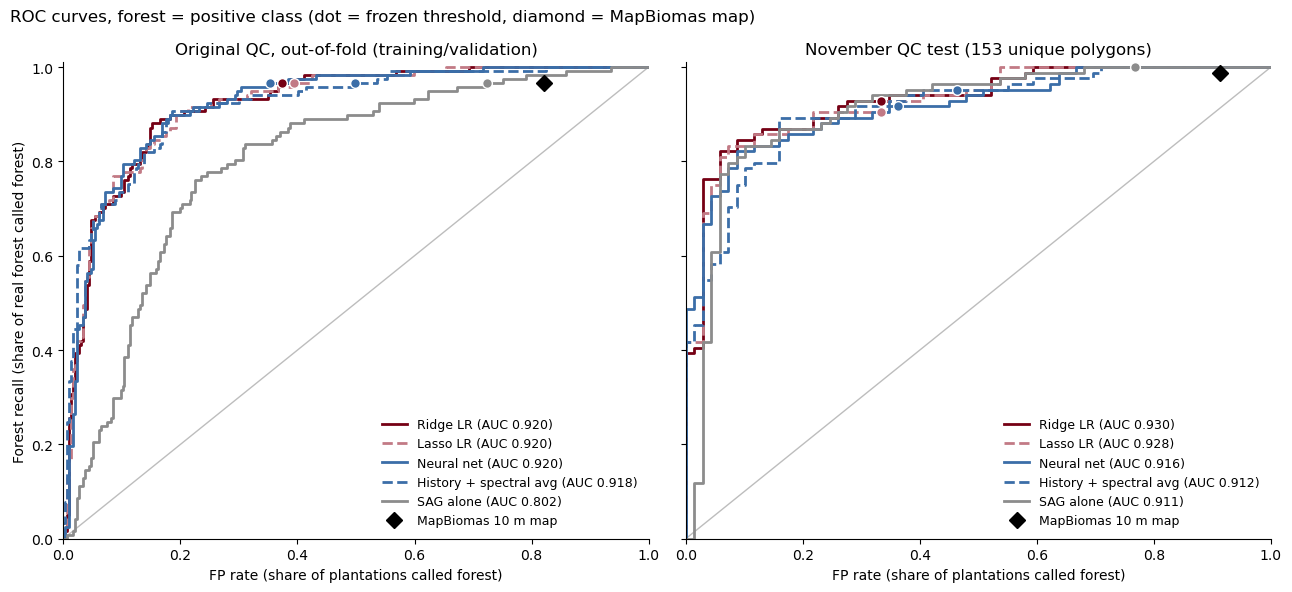

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
panels = [(axes[0], "Original QC, out-of-fold (training/validation)",
           {n: r["oof"][is_qc] for n, r in results.items()}, y[is_qc], mb_pred(qc_train)),
          (axes[1], "November QC test (153 unique polygons)",
           {n: r["p_test"] for n, r in results.items()}, y_test, p_mb_test)]
for ax, title, probs, yy, mbp in panels:
    for name, p in probs.items():
        fpr, tpr, _ = roc_curve(yy, p)
        ax.plot(fpr, tpr, color=COL[name], lw=2, ls="--" if name in DASHED else "-",
                label=f"{name} (AUC {roc_auc_score(yy, p):.3f})")
        cut = p >= FROZEN[name]
        ax.plot(cut[yy == 0].mean(), cut[yy == 1].mean(), "o", color=COL[name], ms=7, mec="white", zorder=5)
    ax.plot(mbp[yy == 0].mean(), mbp[yy == 1].mean(), "D", color=COL["MapBiomas 10 m map"], ms=8,
            label="MapBiomas 10 m map", zorder=6)
    ax.plot([0, 1], [0, 1], color="#BDBDBD", lw=1, zorder=0)
    ax.set(xlim=(0, 1), ylim=(0, 1.01), title=title,
           xlabel="FP rate (share of plantations called forest)")
    ax.legend(loc="lower right", fontsize=9, frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Forest recall (share of real forest called forest)")
fig.suptitle("ROC curves, forest = positive class (dot = frozen threshold, diamond = MapBiomas map)",
             x=0.01, ha="left")
fig.tight_layout(); fig.savefig(f"{OUT}/roc_curves.png", dpi=150); plt.show()

### Same curves in project terms (plantation = what we want to catch)
x = forests called plantation (deforestation we would hide), y = plantations caught (false alarms
removed). The dotted line is the forest-hidden level the cutoffs were set to (MapBiomas's level on
the original QC); each dot is that model's frozen cutoff.

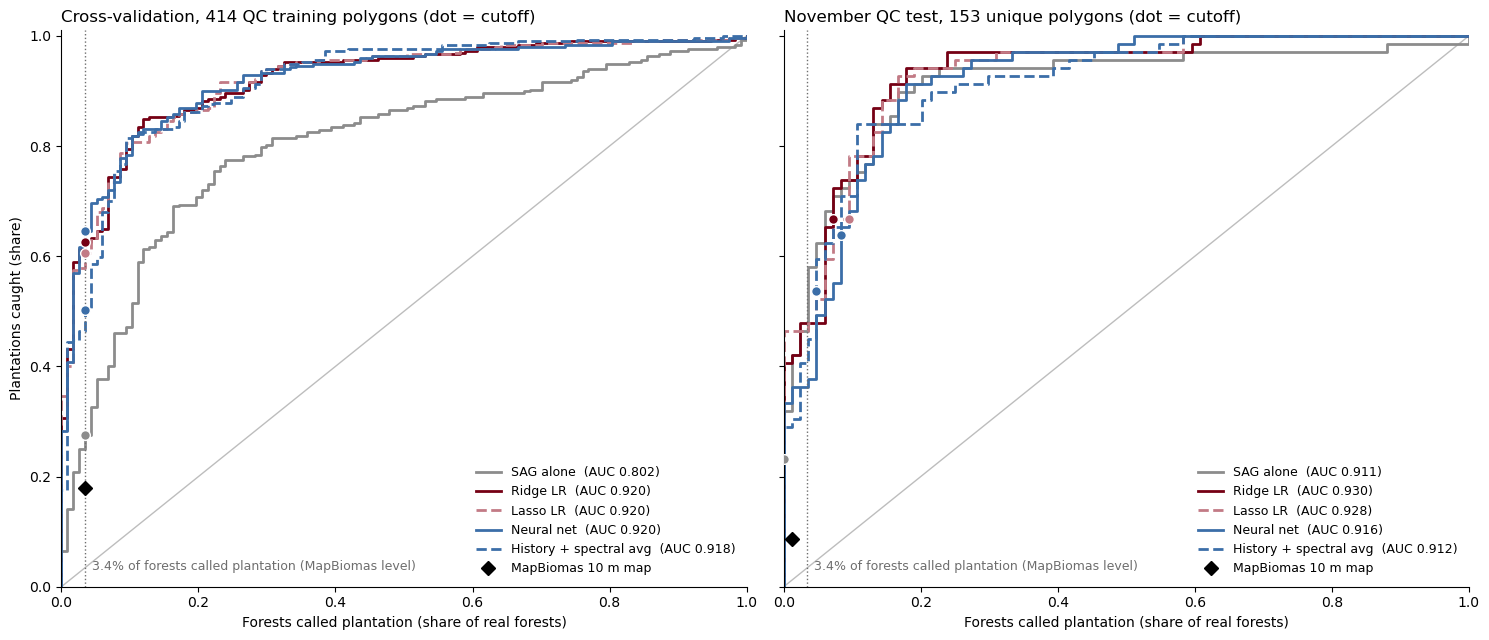

In [15]:
HIDE = 1 - TARGET_RECALL
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)
panels = [(axes[0], f"Cross-validation, {int(is_qc.sum())} QC training polygons (dot = cutoff)",
           {n: r["oof"][is_qc] for n, r in results.items()}, y[is_qc], mb_pred(qc_train)),
          (axes[1], f"November QC test, {len(test)} unique polygons (dot = cutoff)",
           {n: r["p_test"] for n, r in results.items()}, y_test, p_mb_test)]
order = ["SAG alone"] + MODELS
for ax, title, probs, yy, mbp in panels:
    for name in order:
        p = probs[name]
        fpr, tpr, _ = roc_curve(yy == 0, -p)        # plantation positive; low forest score = plantation
        ax.plot(fpr, tpr, color=COL[name], lw=2, ls="--" if name in DASHED else "-",
                label=f"{name}  (AUC {roc_auc_score(yy, p):.3f})")
        flag = p < FROZEN[name]                     # called plantation at the frozen cutoff
        ax.plot(flag[yy == 1].mean(), flag[yy == 0].mean(), "o", color=COL[name], ms=7, mec="white", zorder=5)
    ax.plot((mbp[yy == 1] == 0).mean(), (mbp[yy == 0] == 0).mean(), "D", color=COL["MapBiomas 10 m map"],
            ms=7, label="MapBiomas 10 m map", zorder=6)
    ax.plot([0, 1], [0, 1], color="#BDBDBD", lw=1, zorder=0)
    ax.axvline(HIDE, color="#6E6E6E", ls=":", lw=1)
    ax.text(HIDE + 0.01, 0.03, f"{HIDE:.1%} of forests called plantation (MapBiomas level)",
            color="#6E6E6E", fontsize=9)
    ax.set(xlim=(0, 1), ylim=(0, 1.01), xlabel="Forests called plantation (share of real forests)")
    ax.set_title(title, loc="left")
    ax.legend(loc="lower right", fontsize=9, frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Plantations caught (share)")
fig.tight_layout(); fig.savefig(f"{OUT}/roc_plantations_caught.png", dpi=150); plt.show()

## 12. Feature importance: training/validation vs test
- **Logistic regression:** standardised coefficients of the final models (learned on training data).
- **All models:** permutation importance = drop in AUC when one feature is shuffled (20 repeats).
  "Train QC" uses the final models on the 414 original QC polygons, which they were trained on
  (in-sample, so optimistic); "Test" uses the 153 November polygons.

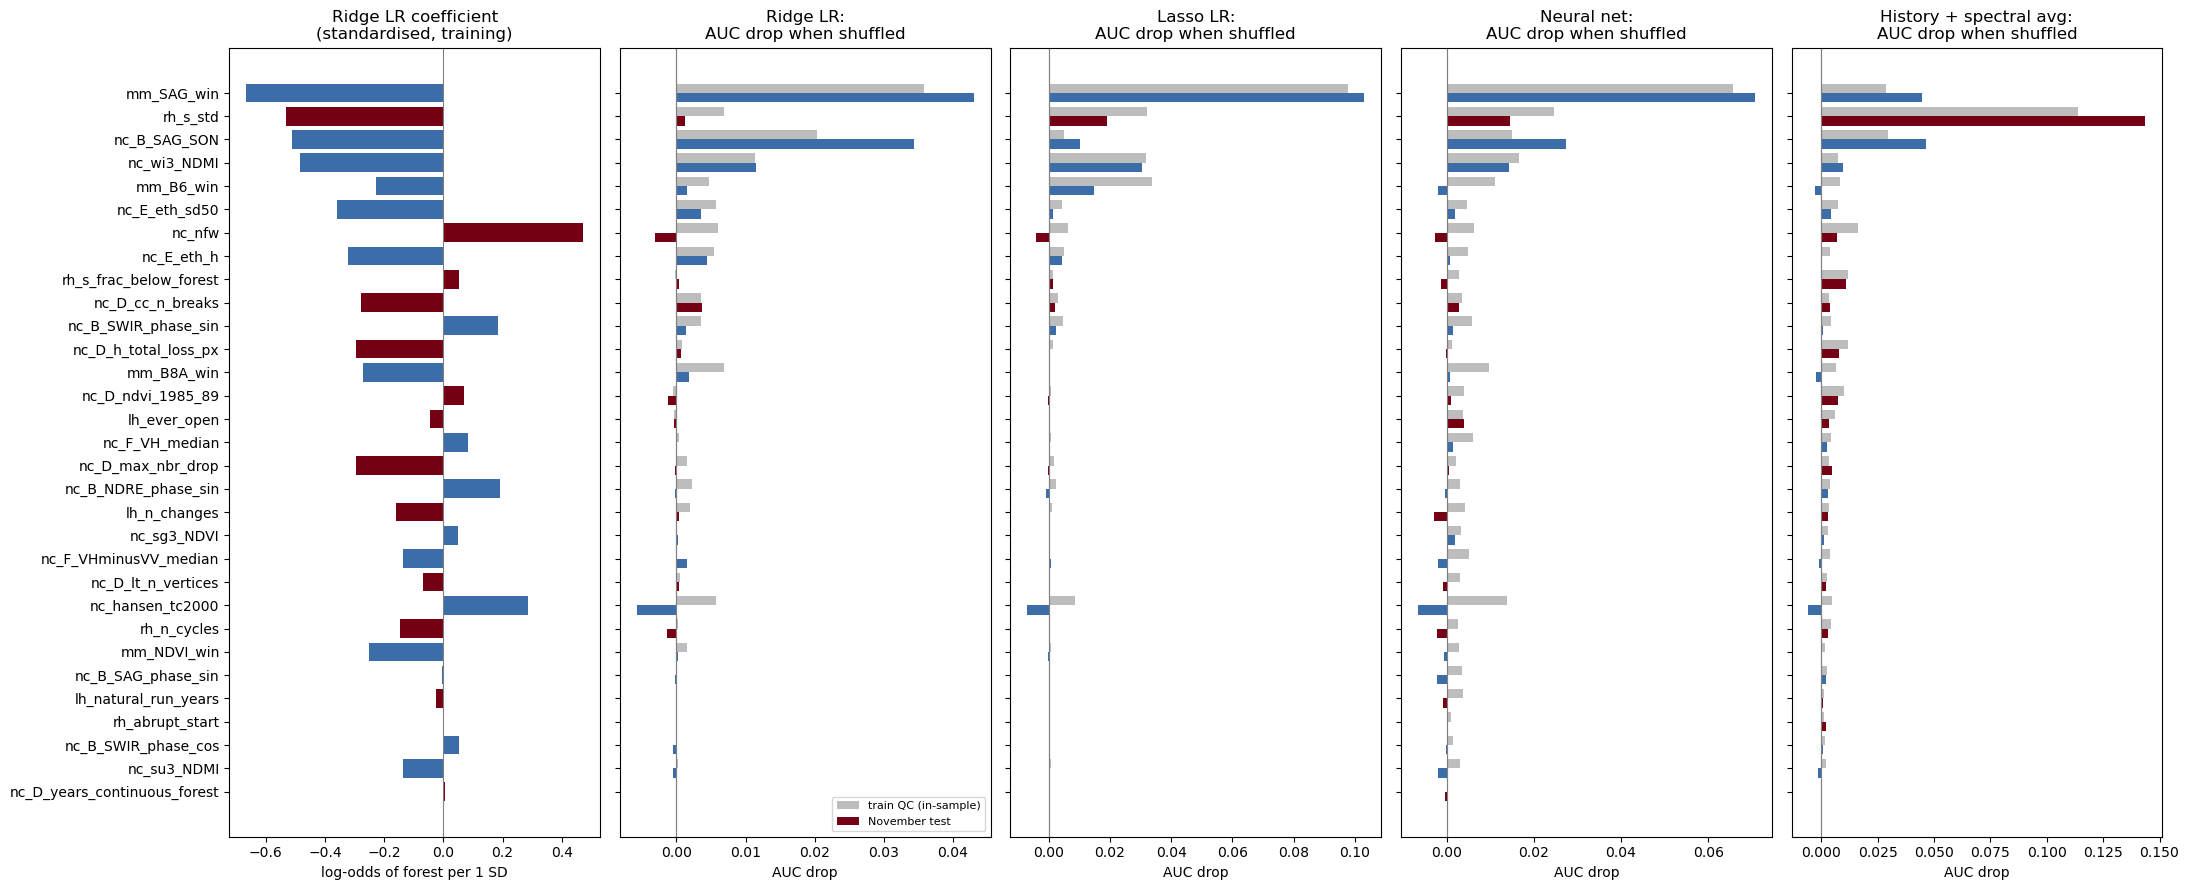

Top 6 features by permutation importance:


,0,1,2,3,4,5
Ridge LR | train QC,mm_SAG_win,nc_B_SAG_SON,nc_wi3_NDMI,mm_B8A_win,rh_s_std,nc_nfw
Ridge LR | test,mm_SAG_win,nc_B_SAG_SON,nc_wi3_NDMI,nc_E_eth_h,nc_D_cc_n_breaks,nc_E_eth_sd50
Lasso LR | train QC,mm_SAG_win,mm_B6_win,rh_s_std,nc_wi3_NDMI,nc_hansen_tc2000,nc_nfw
Lasso LR | test,mm_SAG_win,nc_wi3_NDMI,rh_s_std,mm_B6_win,nc_B_SAG_SON,nc_E_eth_h
Neural net | train QC,mm_SAG_win,rh_s_std,nc_wi3_NDMI,nc_B_SAG_SON,nc_hansen_tc2000,mm_B6_win
Neural net | test,mm_SAG_win,nc_B_SAG_SON,rh_s_std,nc_wi3_NDMI,lh_ever_open,nc_D_cc_n_breaks
History + spectral avg | train QC,rh_s_std,nc_B_SAG_SON,mm_SAG_win,nc_nfw,rh_s_frac_below_forest,nc_D_h_total_loss_px
History + spectral avg | test,rh_s_std,nc_B_SAG_SON,mm_SAG_win,rh_s_frac_below_forest,nc_wi3_NDMI,nc_D_h_total_loss_px


In [16]:
def perm_importance(predict_fn, d, yy, n_repeats=20):
    base = roc_auc_score(yy, predict_fn(d))
    rng = np.random.default_rng(SEED)
    out = {}
    for c in FEATS:
        drops = []
        for _ in range(n_repeats):
            sh = d.copy(); sh[c] = rng.permutation(sh[c].to_numpy())
            drops.append(base - roc_auc_score(yy, predict_fn(sh)))
        out[c] = np.mean(drops)
    return pd.Series(out)

imp = {}
for name, r in ((n, results[n]) for n in MODELS):     # SAG alone uses no model features
    imp[(name, "train QC")] = perm_importance(r["predict"], qc_train, y[is_qc])
    imp[(name, "test")] = perm_importance(r["predict"], test, y_test)
imp = pd.DataFrame(imp)
imp.round(4).to_csv(f"{OUT}/permutation_importance.csv")
coefs.round(4).to_csv(f"{OUT}/lr_coefficients.csv")

order = imp.mean(axis=1).sort_values().index
color = ["#750014" if c in HIST else "#3B6EA8" for c in order]   # burgundy = history, blue = spectral
fig, axes = plt.subplots(1, 5, figsize=(22, 9), sharey=True)
axes[0].barh(order, coefs.loc[order, "Ridge LR"], color=color)
axes[0].set(title="Ridge LR coefficient\n(standardised, training)", xlabel="log-odds of forest per 1 SD")
for ax, name in zip(axes[1:], MODELS):
    ax.barh(np.arange(len(order)) + 0.2, imp.loc[order, (name, "train QC")], 0.4, color="#BDBDBD", label="train QC (in-sample)")
    ax.barh(np.arange(len(order)) - 0.2, imp.loc[order, (name, "test")], 0.4, color=color, label="November test")
    ax.set(title=f"{name}:\nAUC drop when shuffled", xlabel="AUC drop")
    ax.axvline(0, c="gray", lw=0.8)
axes[1].legend(loc="lower right", fontsize=8)
for ax in axes:
    ax.axvline(0, c="gray", lw=0.8)
fig.tight_layout(); fig.savefig(f"{OUT}/feature_importance.png", dpi=150); plt.show()

top = pd.DataFrame({f"{n} | {s}": imp[(n, s)].sort_values(ascending=False).head(6).index.tolist()
                    for n in MODELS for s in ["train QC", "test"]})
print("Top 6 features by permutation importance:")
top.T

## 13. Summary (all 153 test polygons, frozen thresholds)

In [17]:
summary = test_table[test_table.group == "All 153"].set_index("model")[
    ["AUC", "_fp", "_fn", "FP rate at MB recall (test ROC)"]].rename(
    columns={"_fp": "FP rate (fixed thr)", "_fn": "FN rate (fixed thr)"})
summary = summary.join(cv_table.set_index("model")[["QC val AUC (pooled OOF)", "QC OOF FP rate"]])
summary.round(3).to_csv(f"{OUT}/summary.csv")
summary.round(3)

,AUC,FP rate (fixed thr),FN rate (fixed thr),FP rate at MB recall (test ROC),QC val AUC (pooled OOF),QC OOF FP rate
model,,,,,,
MapBiomas 10 m map,0.538,0.913,0.012,0.913,NaN,0.822
Ridge LR,0.930,0.333,0.071,0.580,0.920,0.374
Lasso LR,0.928,0.333,0.095,0.536,0.920,0.394
Neural net,0.916,0.362,0.083,0.638,0.920,0.354
History + spectral avg,0.912,0.464,0.048,0.696,0.918,0.498
SAG alone,0.911,0.768,0.000,0.580,0.802,0.724
